# 小さな GPT を日本語のテキストでゼロから事前学習する (学習ループを自分で書く)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/B_implementations/gpt_scratch.ipynb)

NLP クックブック B-07 ／ 仕組みを理解するための実装

> GPU ランタイム推奨 (ランタイム → ランタイムのタイプを変更 → T4 GPU)

事前学習済みのモデルを使うだけでなく、言語モデルがテキストから何を学んでいくのかを自分の手で確かめたい。日本語版 Wikipedia の一部でトークナイザーを作り、1,400 万パラメータほどの GPT をゼロから学習して、損失・パープレキシティと生成される文章の変化を見る。

In [1]:
!pip install -q datasets

In [2]:
import random
import numpy as np
import torch
from datasets import load_dataset

random.seed(0); np.random.seed(0); torch.manual_seed(0)

# 日本語版 Wikipedia (wikimedia/wikipedia の 20231101.ja。本文は CC BY-SA 3.0 と GFDL)
# ストリーミングで 25,000 記事を取り出し、短い記事を除いて、各記事の先頭 2,000 文字だけを使う (1 分ほど)
wiki = load_dataset("wikimedia/wikipedia", "20231101.ja", split="train", streaming=True)
texts = [a["text"][:2000] for a in wiki.shuffle(seed=0, buffer_size=10000).take(25000) if len(a["text"]) >= 300]
train_texts, val_texts = texts[:-500], texts[-500:]   # 最後の 500 記事を検証用に取っておく
print(len(train_texts), "記事 (学習) /", len(val_texts), "記事 (検証)", f"学習データ {sum(map(len, train_texts)) / 1e6:.1f}M 文字")
print(train_texts[0][:100])

21937 記事 (学習) / 500 記事 (検証) 学習データ 29.2M 文字
当摩 広麻呂（たいま/たぎま の ひろまろ）は、飛鳥時代後期の人物。氏は当麻とも書く。姓は公のち真人。用明天皇の皇子である当麻皇子（麻呂子皇子）の孫とする系図がある。冠位は直大参、贈直大壱。

壬申の


In [3]:
from tokenizers import Tokenizer, decoders, models, normalizers, pre_tokenizers, trainers
from transformers import PreTrainedTokenizerFast

# GPT-2 と同じバイト単位の BPE。どんな文字もバイト列に戻せるので、未知語 ([UNK]) が出ない
bpe = Tokenizer(models.BPE())
bpe.normalizer = normalizers.NFKC()                                   # 全角英数字などを半角にそろえる
bpe.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe.decoder = decoders.ByteLevel()
trainer = trainers.BpeTrainer(vocab_size=8000, special_tokens=["<|endoftext|>"],
                              initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False)
bpe.train_from_iterator(train_texts[:8000], trainer)                  # 語彙は学習データの一部 8,000 記事から作る (Colab で 1 分以内)
tokenizer = PreTrainedTokenizerFast(tokenizer_object=bpe, bos_token="<|endoftext|>", eos_token="<|endoftext|>")

ids = tokenizer("吾輩は猫である。自然言語処理は人工知能の一分野である。")["input_ids"]
print(len(ids), "トークン:", [tokenizer.decode([i]) for i in ids])

18 トークン: ['吾', '輩', 'は', '猫', 'である', '。', '自然', '言語', '処理', 'は', '人', '工', '知', '能', 'の一', '分野', 'である', '。']


In [4]:
# 全記事をトークン ID にし、記事の間に <|endoftext|> を挟んでつなげ、256 トークンずつのブロックに切る
BLOCK = 256
def to_blocks(texts):
    ids = np.concatenate([x + [tokenizer.eos_token_id] for x in tokenizer(texts)["input_ids"]])
    n = len(ids) // BLOCK * BLOCK
    return torch.tensor(ids[:n], dtype=torch.long).view(-1, BLOCK), len(ids)

train_data, n_train = to_blocks(train_texts)
val_data, n_val = to_blocks(val_texts)
val_chars = sum(len(t) for t in val_texts)
print(f"学習 {n_train / 1e6:.1f}M トークン ({train_data.shape[0]} ブロック) / 検証 {n_val / 1e3:.0f}K トークン")
print(f"1 トークンあたり {val_chars / n_val:.2f} 文字")

# 比較の基準: 文脈を見ずにトークンの出現頻度だけで予測するモデル (ユニグラム) のパープレキシティ
counts = torch.bincount(train_data.flatten(), minlength=len(tokenizer)).float() + 1
unigram_loss = -(counts / counts.sum()).log()[val_data.flatten()].mean().item()
print(f"ユニグラムのパープレキシティ: {np.exp(unigram_loss):.0f} (語彙 {len(tokenizer)})")

学習 18.8M トークン (73297 ブロック) / 検証 438K トークン
1 トークンあたり 1.55 文字
ユニグラムのパープレキシティ: 1842 (語彙 8000)


In [5]:
from transformers import GPT2Config, GPT2LMHeadModel

device = "cuda"
BF16 = torch.cuda.get_device_capability()[0] >= 8    # T4 は bf16 が使えないので float16 + 損失のスケーリング
config = GPT2Config(vocab_size=len(tokenizer), n_positions=BLOCK, n_embd=384, n_layer=6, n_head=6,
                    resid_pdrop=0.0, embd_pdrop=0.0, attn_pdrop=0.0,           # データを 2 周ほどしか見ないのでドロップアウトなし
                    bos_token_id=tokenizer.bos_token_id, eos_token_id=tokenizer.eos_token_id)
torch.manual_seed(0)
model = GPT2LMHeadModel(config).to(device)            # from_pretrained ではなく、設定から重みがランダムなモデルを作る
n_params = sum(p.numel() for p in model.parameters())
n_emb = model.transformer.wte.weight.numel() + model.transformer.wpe.weight.numel()
print(f"{n_params / 1e6:.1f}M パラメータ (うち埋め込み {n_emb / 1e6:.1f}M。出力層は入力の埋め込みと重みを共有)")

13.8M パラメータ (うち埋め込み 3.2M。出力層は入力の埋め込みと重みを共有)


In [6]:
import math, time

STEPS, BATCH, LR, WARMUP = 5000, 32, 1e-3, 200
opt = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.1)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min((s + 1) / WARMUP, 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * s / STEPS))))
scaler = torch.amp.GradScaler(enabled=not BF16)
amp = dict(device_type="cuda", dtype=torch.bfloat16 if BF16 else torch.float16)

@torch.no_grad()
def evaluate(data, max_blocks=None):
    """検証データの 1 トークンあたりの平均損失 (負対数尤度、自然対数)"""
    model.eval()
    losses = [model(input_ids=x.to(device), labels=x.to(device)).loss.item() for x in data[:max_blocks].split(64)]
    model.train()
    return float(np.mean(losses))

prompts = ["日本の首都は", "猫は"]
SAMPLING = dict(do_sample=True, temperature=0.8, top_p=0.95, top_k=0)
@torch.no_grad()
def sample(prompt, seed=0, **kwargs):
    """プロンプトの続きを 40 トークン生成する (kwargs は generate に渡すデコードの設定)"""
    model.eval()
    torch.manual_seed(seed)                      # 生成用の乱数 (データの順番は下の data_gen で別に管理する)
    ids = tokenizer(tokenizer.bos_token + prompt, return_tensors="pt", return_token_type_ids=False).to(device)
    out = model.generate(**ids, max_new_tokens=40, pad_token_id=tokenizer.eos_token_id, **kwargs)
    model.train()
    return tokenizer.decode(out[0, 1:], skip_special_tokens=True).replace("\n", " ")

log, samples, recent = [], {}, []        # log: (ステップ, 検証の損失, 直前の区間の学習の損失の平均, 経過秒)
step, t0 = 0, time.time()
data_gen = torch.Generator().manual_seed(0)   # データの順番専用の乱数。sample() の manual_seed の影響を受けない
model.train()
# T4 で 15 分ほど (A5000 で 4 分強から見積もり。最初に出る loss_type=None の警告は無害)
while step < STEPS:
    for idx in torch.randperm(len(train_data), generator=data_gen).split(BATCH):          # 1 周 (エポック) ごとにブロックの順番をシャッフル
        if step % 250 == 0 or step in (50, 100):
            train_loss = torch.stack(recent).mean().item() if recent else float("nan"); recent = []
            log.append((step, evaluate(val_data, 200), train_loss, time.time() - t0))   # 検証は先頭 200 ブロック (約 5 万トークン) で概算
            print(f"step {step:5}  学習の損失 {train_loss:.3f}  検証の損失 {log[-1][1]:.3f}  検証 PPL {math.exp(log[-1][1]):7.1f}  {log[-1][3]:4.0f} 秒")
        if step in (0, 100, 500, 1000, 2500):
            samples[step] = [sample(p, **SAMPLING) for p in prompts]
        if step == STEPS:
            break
        x = train_data[idx].to(device)
        with torch.autocast(**amp):
            loss = model(input_ids=x, labels=x).loss
        recent.append(loss.detach())
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        step += 1
samples[STEPS] = [sample(p, **SAMPLING) for p in prompts]
val_loss = evaluate(val_data)
print(f"学習 {step} ステップ ({step * BATCH / len(train_data):.1f} エポック)、{time.time() - t0:.0f} 秒、GPU メモリ {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
print(f"検証データ全体: 損失 {val_loss:.3f}  PPL {math.exp(val_loss):.1f}  1 文字あたり {val_loss * n_val / val_chars / math.log(2):.2f} bit")   # 文字数は正規化前の元の文字数

step     0  学習の損失 nan  検証の損失 9.070  検証 PPL  8692.2     1 秒
step    50  学習の損失 8.153  検証の損失 7.431  検証 PPL  1687.2     5 秒
step   100  学習の損失 7.171  検証の損失 6.893  検証 PPL   985.5     7 秒
step   250  学習の損失 6.380  検証の損失 6.014  検証 PPL   409.1    14 秒
step   500  学習の損失 5.712  検証の損失 5.393  検証 PPL   219.8    26 秒
step   750  学習の損失 5.250  検証の損失 5.083  検証 PPL   161.3    38 秒
step  1000  学習の損失 4.970  検証の損失 4.841  検証 PPL   126.6    50 秒
step  1250  学習の損失 4.766  検証の損失 4.677  検証 PPL   107.4    62 秒
step  1500  学習の損失 4.594  検証の損失 4.519  検証 PPL    91.7    74 秒
step  1750  学習の損失 4.464  検証の損失 4.414  検証 PPL    82.6    87 秒
step  2000  学習の損失 4.350  検証の損失 4.297  検証 PPL    73.5    99 秒
step  2250  学習の損失 4.221  検証の損失 4.176  検証 PPL    65.1   112 秒
step  2500  学習の損失 4.069  検証の損失 4.086  検証 PPL    59.5   124 秒
step  2750  学習の損失 3.963  検証の損失 4.012  検証 PPL    55.3   137 秒
step  3000  学習の損失 3.927  検証の損失 3.939  検証 PPL    51.4   149 秒
step  3250  学習の損失 3.869  検証の損失 3.879  検証 PPL    48.4   162 秒
step  3500  学習の損失 3.812  検

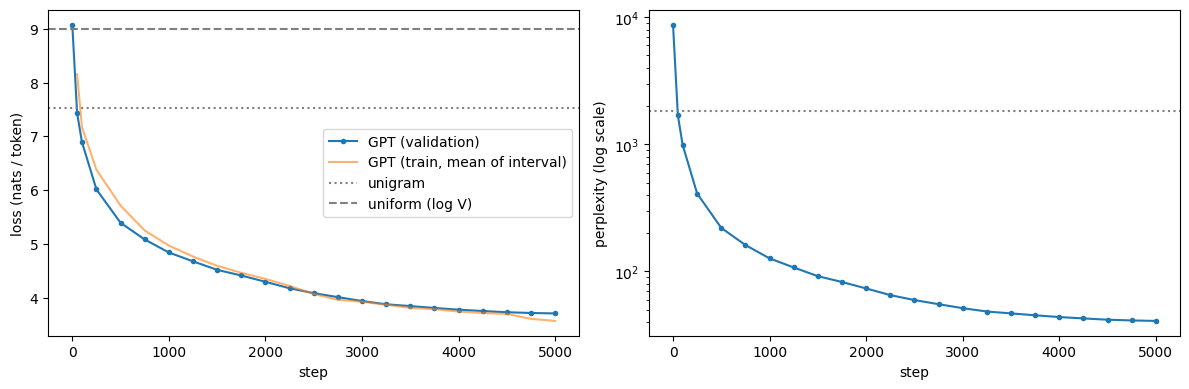

In [7]:
import matplotlib.pyplot as plt

steps, losses, train_losses, _ = zip(*log)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(steps, losses, "o-", ms=3, label="GPT (validation)")
axes[0].plot(steps, train_losses, "-", alpha=0.6, label="GPT (train, mean of interval)")
axes[0].axhline(unigram_loss, color="gray", ls=":", label="unigram")
axes[0].axhline(math.log(len(tokenizer)), color="gray", ls="--", label="uniform (log V)")
axes[0].set_xlabel("step"); axes[0].set_ylabel("loss (nats / token)"); axes[0].legend()
axes[1].plot(steps, np.exp(losses), "o-", ms=3)
axes[1].axhline(np.exp(unigram_loss), color="gray", ls=":")
axes[1].set_yscale("log"); axes[1].set_xlabel("step"); axes[1].set_ylabel("perplexity (log scale)")
plt.tight_layout(); plt.show()

In [8]:
# 学習の途中で生成した文章 (同じ乱数の種で、temperature 0.8、top_p 0.95 のサンプリング)
val_at = {s: v for s, v, _, _ in log}          # ステップ → 検証の損失 (先頭 200 ブロック)
for s, outs in samples.items():
    print(f"--- step {s} (検証 PPL {math.exp(val_at[s]):.0f})")
    for o in outs:
        print("  ", o)

--- step 0 (検証 PPL 8692)
   日本の首都は全て古代塁の教員500上はすることがものでx集団盛バイパス苦妖できないを受けた天井をオー次郎上が艦早稲田全国高等学校ぞコミュニティ頻付けの�メートルそれを騎かし討払区の佐野稲孫マラ
   猫は簿古代塁の教員500上はすることがものでx集団盛バイパス苦妖できない役割YOをオー次郎上が艦早稲田全国高等学校磐コミュニティ上げる2010抑カラそれを騎原子の死払区の佐野稲孫がっ
--- step 100 (検証 PPL 985)
   日本の首都はが古代。     x          関連項目 イ次郎 ホイメ  国立2010年   概    .  
   猫はが古代。                関連項目 イ次郎 ホイメ  国立2010年  ERat ワ  .  
--- step 500 (検証 PPL 220)
   日本の首都は、古代炭剤によって塩生物に水圧により、原子武材で、を造させる艦、メイヨ・マチサウル、爆大陸、N・マラ
   猫は、古代神経の物の生物に水心法、有武材で、をほとんど感なうものもいう。  歴史  花植物 大東亜素  
--- step 1000 (検証 PPL 127)
   日本の首都は、古代日本の俳優。フランス系。プロレスライダー。東京都出身。父は元プロレスをイューン艦。ポジションは、現役後世中。ポジションはウルワローズ、Nova
   猫は、古代日本の俳優。フランス語。プロレスライダー。東京都出身。父は元プロレスを所属するプロレスの会(ABC)でプロレスプロレス選手(Datads of H.JAP
--- step 2500 (検証 PPL 60)
   日本の首都は、福岡県横浜市茂原市にある、北陸地方のバイパスである。  概要  佐久浦町の交点は、北陸道の国道1号(東亜空港)の
   猫は、古代ローマ期限界から、その集団により、アフリカにかけて広く発展したことはほとんどない。ホイソでは、頻繁に食死し、現代には様々な存在がなかった。
--- step 5000 (検証 PPL 41)
   日本の首都は、福岡県北九州市西区に本部を置く日本のプロサッカーリーグで、サッカー団体である。  概要  Jリーグの開催であり、近畿地方放送(東九州市・下
   猫は全てのごとくえんりする

In [9]:
# この章の「言語モデルで文の自然さ (パープレキシティ) を測る」と同じ文で、自分で学習したモデルの確率を見る
@torch.no_grad()
def score(text):
    ids = tokenizer(tokenizer.bos_token + text, return_tensors="pt")["input_ids"].to(device)
    loss = model(ids, labels=ids).loss.item()
    n = ids.shape[1] - 1
    return -loss * n, n, math.exp(loss)

model.eval()
for text in ["吾輩は猫である。名前はまだ無い。", "吾輩は猫がある。名前をまだ無い。", "無いまだは名前。である猫は吾輩。"]:
    ll, n, ppl = score(text)
    print(f"対数尤度 {ll:8.2f}  トークン数 {n:2}  PPL {ppl:8.1f}  {text}")
pairs = [("太郎が本を読んだ。", "太郎が本が読んだ。"), ("私は昨日学校に行った。", "私は昨日学校に行く。"),
         ("3 冊の本を買った。", "3 匹の本を買った。"), ("雨が降ったので、試合は中止になった。", "雨が降ったのに、試合は中止になった。")]
for good, bad in pairs:
    print("○" if score(good)[0] > score(bad)[0] else "×", good, "/", bad)

# この章の「テキスト生成のデコード方法 (貪欲法・ビームサーチ・サンプリング) を比べる」と同じく、デコードの方法で出力が変わる
for label, kw in [("貪欲法", dict(do_sample=False)), ("貪欲法 + no_repeat_ngram_size=3", dict(do_sample=False, no_repeat_ngram_size=3)),
                  ("サンプリング (temperature 0.8)", SAMPLING)]:
    print(f"{label:30}", sample("日本の首都は", **kw))

対数尤度   -64.08  トークン数 12  PPL    208.5  吾輩は猫である。名前はまだ無い。
対数尤度   -71.80  トークン数 12  PPL    396.7  吾輩は猫がある。名前をまだ無い。
対数尤度   -86.70  トークン数 12  PPL   1373.6  無いまだは名前。である猫は吾輩。
○ 太郎が本を読んだ。 / 太郎が本が読んだ。
× 私は昨日学校に行った。 / 私は昨日学校に行く。
○ 3 冊の本を買った。 / 3 匹の本を買った。
○ 雨が降ったので、試合は中止になった。 / 雨が降ったのに、試合は中止になった。
貪欲法                            日本の首都は、日本の首都圏(旧称)が運営する、日本の地方自治体(自治体)である。  概要  東京都港区にある、東京都港区にある、東京都港区にある、東京都港区
貪欲法 + no_repeat_ngram_size=3   日本の首都は、日本の首都圏(旧称)が運営する、日本の地方自治体(自治体)である。  概要  東京都港区にある、東京都港区と東京都港区の境界にある。
サンプリング (temperature 0.8)       日本の首都は、福岡県北九州市西区に本部を置く日本のプロサッカーリーグで、サッカー団体である。  概要  Jリーグの開催であり、近畿地方放送(東九州市・下


- 言語モデルの事前学習は「次のトークンを当てる」分類の繰り返し。`labels=input_ids` を渡すと、1 つずらした交差エントロピー (Transformers の基本操作の章の「言語モデルで文の自然さ (パープレキシティ) を測る」と同じ平均負対数尤度) が返る。重みがランダムな学習前のモデルの検証の損失は 9.070 (PPL 8,692) で、語彙 8,000 から一様に選ぶ場合の log 8000 ≈ 8.99 にほぼ等しい。
- 50 ステップで検証 PPL が 1,687 と出現頻度だけのユニグラム (1,842) を下回り、5,000 ステップ (2.2 エポック) で検証データ全体の PPL は 41.9 になった (学習中の表示は先頭 200 ブロックでの概算)。学習の損失 (直前 250 ステップの平均) は 1 周目を終えた直後の 2,500 ステップで検証の損失を下回り、3 周目に入った 4,582 ステップの後は、差が 4,500 ステップの 0.03 から最後の 0.14 (学習 3.570、検証 3.709) に開いた。同じデータを繰り返し見ると過学習が進むので、さらに下げるにはデータとステップ数を一緒に増やす必要がある (この実験では確かめていない)。
- 生成文の変化: 学習前はでたらめなトークンの列 (バイトの切れ端が `�` になる)、100 ステップでは「関連項目」「概」のような頻出の断片と空白が並ぶだけ、1,000 ステップで「東京都出身。父は…」のような人物記事の書式が現れる。5,000 ステップでは「日本の首都は、福岡県北九州市西区に本部を置く日本のプロサッカーリーグで、サッカー団体である。」と文の形は整うが、内容は誤っている。この規模では、知識より先に書式や文の形を覚える。
- バイト単位の BPE (GPT-2 と同じ方式) で語彙 8,000 にすると、1 トークンあたり 1.55 文字で、「吾輩」「人工知能」は 1 文字ずつに分かれた (トークナイザーの学習はサブワードとトークナイザの章の「Hugging Face tokenizers で BPE / WordPiece を学習する」も参照)。トークンあたりの PPL はトークナイザーで変わるので、分割の違うモデルと比べるときは 1 文字あたりのビット数 (ここでは 3.47 bit) にそろえる。
- Transformers の基本操作の章の「言語モデルで文の自然さ (パープレキシティ) を測る」と同じ 3 文では、PPL が正しい文 208.5、助詞を誤った文 396.7、語順を崩した文 1,373.6 の順になった。最小対は 4 組中 3 組で正しい文を選び、「昨日〜行った / 行く」の時制は外した。4 組では何も言えないので、系統的に調べるならTransformers の基本操作の章の「言語モデルの文法知識を最小対で調べる (BLiMP / JBLiMP)」の方法を使う。
- 貪欲法では「東京都港区にある、」を繰り返すループに陥った。`no_repeat_ngram_size=3` で同じ並びの繰り返しは止まるが、「東京都港区と東京都港区の境界」のような形を変えた繰り返しは残る。小さなモデルほど繰り返しに陥りやすく、Transformers の基本操作の章の「テキスト生成のデコード方法 (貪欲法・ビームサーチ・サンプリング) を比べる」のサンプリングの設定が効いてくる。
- 13.8M パラメータ (うち埋め込み 3.2M)、学習中の GPU メモリは 2.7 GB。検証のマシン (RTX A5000、T4 と同じ float16 の経路) で学習のセルは 251 秒 (1 ステップ約 50ms) で、T4 はこれより遅い。ここに書いた数値と生成文はこのマシンでの 1 回の結果で、GPU が違うと計算の細部が変わり、生成文や最小対の結果は別のものになりうる。
- 学習したトークンは延べ 4,100 万 (重複しないのは 1,880 万) で、パラメータ数の約 3 倍 (重複なしでは約 1.4 倍)。Chinchilla (Hoffmann et al., 2022) は 70B パラメータを 1.4 兆トークン (約 20 倍) で学習しており、それに比べるとデータがかなり少ない。エンコーダー・デコーダーをゼロから学習する例は、機械翻訳の章の「Transformer の翻訳モデルをゼロから学習する」にある。
- データは日本語版 Wikipedia (wikimedia/wikipedia の 20231101.ja、データセットカードによれば本文は GFDL と CC BY-SA 3.0)。読み込みはTransformers の基本操作の章の「巨大なデータセットをダウンロードせずにストリーミングで読む」と同じストリーミングで、`shuffle` はバッファ内の近似的なシャッフル。各記事の先頭 2,000 文字だけを使っているので、記事の冒頭 (定義文) に偏っている。
- 実務でライブラリを使って同じことをする版は、Transformers の基本操作の章の「統制した自前のコーパスで小さな GPT を事前学習する (Trainer)」。